# 销售趋势分析

按月统计订单量与销售额（仅 delivered 订单，2016 年数据不完整故从 2017 年起分析）。

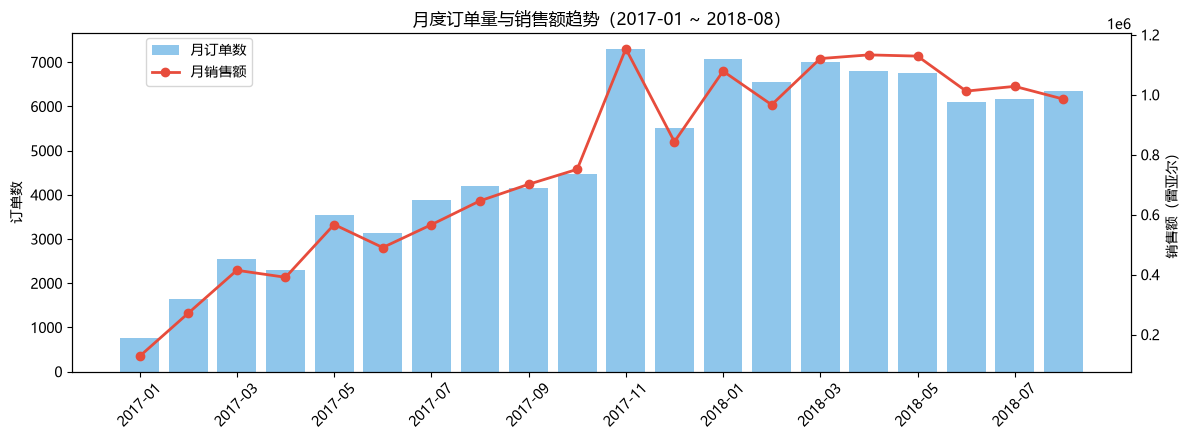

2017 全年订单 43,428，销售额 6,922,900
2018 年 1-8 月订单 52,783，销售额 8,452,975
峰值月 2017-11：7,289 单


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

orders = pd.read_csv('data/orders_clean.csv', parse_dates=['order_purchase_timestamp'])
payments = pd.read_csv('data/order_payments_clean.csv')

o = orders[orders['order_status'] == 'delivered'].drop_duplicates('order_id')
o['rev'] = o['order_id'].map(payments.groupby('order_id')['payment_value'].sum())
o['ym'] = o['order_purchase_timestamp'].dt.to_period('M')
m = o.groupby('ym').agg(订单数=('order_id', 'nunique'), 销售额=('rev', 'sum'))
m = m[m.index >= '2017-01']

x = [str(i) for i in m.index]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x, m['订单数'], color='#3498db', alpha=.55, label='月订单数')
ax2 = ax.twinx()
ax2.plot(x, m['销售额'], color='#e74c3c', marker='o', lw=2, label='月销售额')
ax.set_xticks(x[::2]); ax.set_xticklabels(x[::2], rotation=45)
ax.set_ylabel('订单数'); ax2.set_ylabel('销售额（雷亚尔）')
ax.set_title('月度订单量与销售额趋势（2017-01 ~ 2018-08）')
fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.92))
plt.tight_layout(); plt.show()

print(f"2017 全年订单 {m.loc['2017-01':'2017-12', '订单数'].sum():,}，销售额 {m.loc['2017-01':'2017-12', '销售额'].sum():,.0f}")
print(f"2018 年 1-8 月订单 {m.loc['2018-01':'2018-08', '订单数'].sum():,}，销售额 {m.loc['2018-01':'2018-08', '销售额'].sum():,.0f}")
print(f"峰值月 {m['订单数'].idxmax()}：{m['订单数'].max():,} 单")


## 结论

- **增长明显**：2017 全年 43,428 单 / 692 万雷亚尔（月均 3,619 单）→ 2018 年 1-8 月 52,783 单 / 845 万雷亚尔（月均 6,598 单），月订单量接近翻倍。
- **黑五效应**：峰值月为 2017-11（7,289 单），黑色星期五促销拉动显著。
- **进入平台期**：2018 年 3 月后月订单量稳定在 6,000–7,000 区间，增速放缓。
- 2018-09 起数据被截断，不纳入趋势判断。

## 业务解读

- 2017→2018 月订单量接近翻倍（3,619 → 6,598）且客单价稳定（销售额同步增长），说明增长由**订单量驱动而非涨价**，是健康的规模扩张。
- 黑五月（2017-11 峰值 7,289 单）显示促销是核心流量抓手，巴西零售的「黑五文化」显著。
- 2018-03 后月订单量进入 6,000–7,000 平台期——获客增长放缓，此时增长杠杆应从拉新转向复购（见复购留存）与客单价（见交叉销售）。
- 对供应链的含义：月 6k±500 的订单节奏意味着仓储与物流产能可按此基线规划，促销月需 +20% 弹性。

C:\Users\admin\AppData\Local\Temp\ipykernel_87364\2396751617.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dow = o['order_purchase_timestamp'].dt.dayofweek


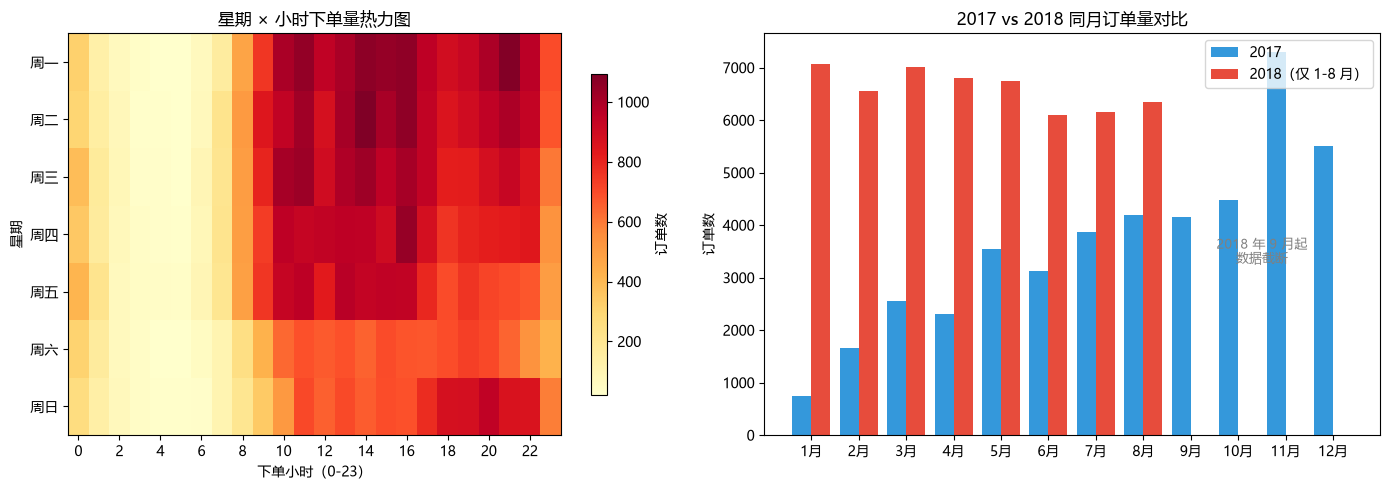

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 星期 × 小时下单热力图
dow = o['order_purchase_timestamp'].dt.dayofweek
hour = o['order_purchase_timestamp'].dt.hour
hm = o.assign(dow=dow, hour=hour).pivot_table(index='dow', columns='hour',
                                              values='order_id', aggfunc='count')
im = axes[0].imshow(hm.values, aspect='auto', cmap='YlOrRd')
axes[0].set_yticks(range(7), ['周一', '周二', '周三', '周四', '周五', '周六', '周日'])
axes[0].set_xticks(range(0, 24, 2), range(0, 24, 2))
axes[0].set_xlabel('下单小时（0-23）'); axes[0].set_ylabel('星期')
axes[0].set_title('星期 × 小时下单量热力图')
plt.colorbar(im, ax=axes[0], shrink=.8, label='订单数')

# ② 2017 vs 2018 同月订单量对比（2018 仅 1-8 月）
mm = m.copy()
mm['月'] = mm.index.month
piv = mm.pivot_table(index='月', columns=mm.index.year, values='订单数')
xs = np.arange(12)
axes[1].bar(xs - .2, piv[2017].values, .4, label='2017', color='#3498db')
v18 = piv[2018].reindex(range(1, 13)).fillna(0)
axes[1].bar(xs + .2, v18.values, .4, label='2018（仅 1-8 月）', color='#e74c3c')
axes[1].set_xticks(xs, [f'{i}月' for i in range(1, 13)])
axes[1].set_ylabel('订单数'); axes[1].set_title('2017 vs 2018 同月订单量对比')
axes[1].text(9.5, piv[2017].max() * .45, '2018 年 9 月起\n数据截断', ha='center',
             fontsize=9, color='gray')
axes[1].legend()

plt.tight_layout()
plt.show()